# Inspecting training data 
Modified from the [Inspect_training_data notebook](https://knowledge.dea.ga.gov.au/notebooks/Real_world_examples/Scalable_machine_learning/2_Inspect_training_data/) in the DEA Sandbox Machine Learning example

## Getting started

To run this analysis, run all the cells in the notebook, starting with the "Load packages" cell. 

## Load packages

In [24]:
%matplotlib inline
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
import seaborn as sns

## Analysis Parameters

* `training_data`: Name and location of the training data `.csv` file output from runnning `Age_Classification.ipynb`.
* `class_dict`: A dictionary mapping the 'string' name of the classes to the integer values that represent our classes in the training data (e.g. `{'crop': 1., 'noncrop': 0.}`)
* `field`: This is the name of the column in the original training data shapefile that contains the class labels. This is provided simply so we can remove this attribute before we plot the data

In [2]:
training_data = "Results/training_data.csv"

class_dict = {'fallow': 0, '1 yr old': 1, '2 yr old': 2}

field = 'CLASS_ID'

## Import training data


In [3]:
df = pd.read_csv(training_data)

## Data Wrangling

This cell extracts each class in the training data array and assigns it to a dictionary, this step will allow for cleanly plotting our data

In [4]:
# Fit the standard scaler to all features
X = df.drop(field, axis=1)
y = df[[field]]
scaler = StandardScaler(with_mean=False)
scaler.fit(X);

dfs = {}
for key, value in class_dict.items():
    print(key, value)
    # extract values for class from training data
    arr = df[df[field]==value].drop(field, axis=1)
    # Scale the dataframe
    scaled_df = scaler.transform(arr)
    scaled_df = pd.DataFrame(scaled_df, columns=arr.columns)
    
    dfs.update({key:scaled_df})

fallow 0
1 yr old 1
2 yr old 2


## Feature layer violin plots

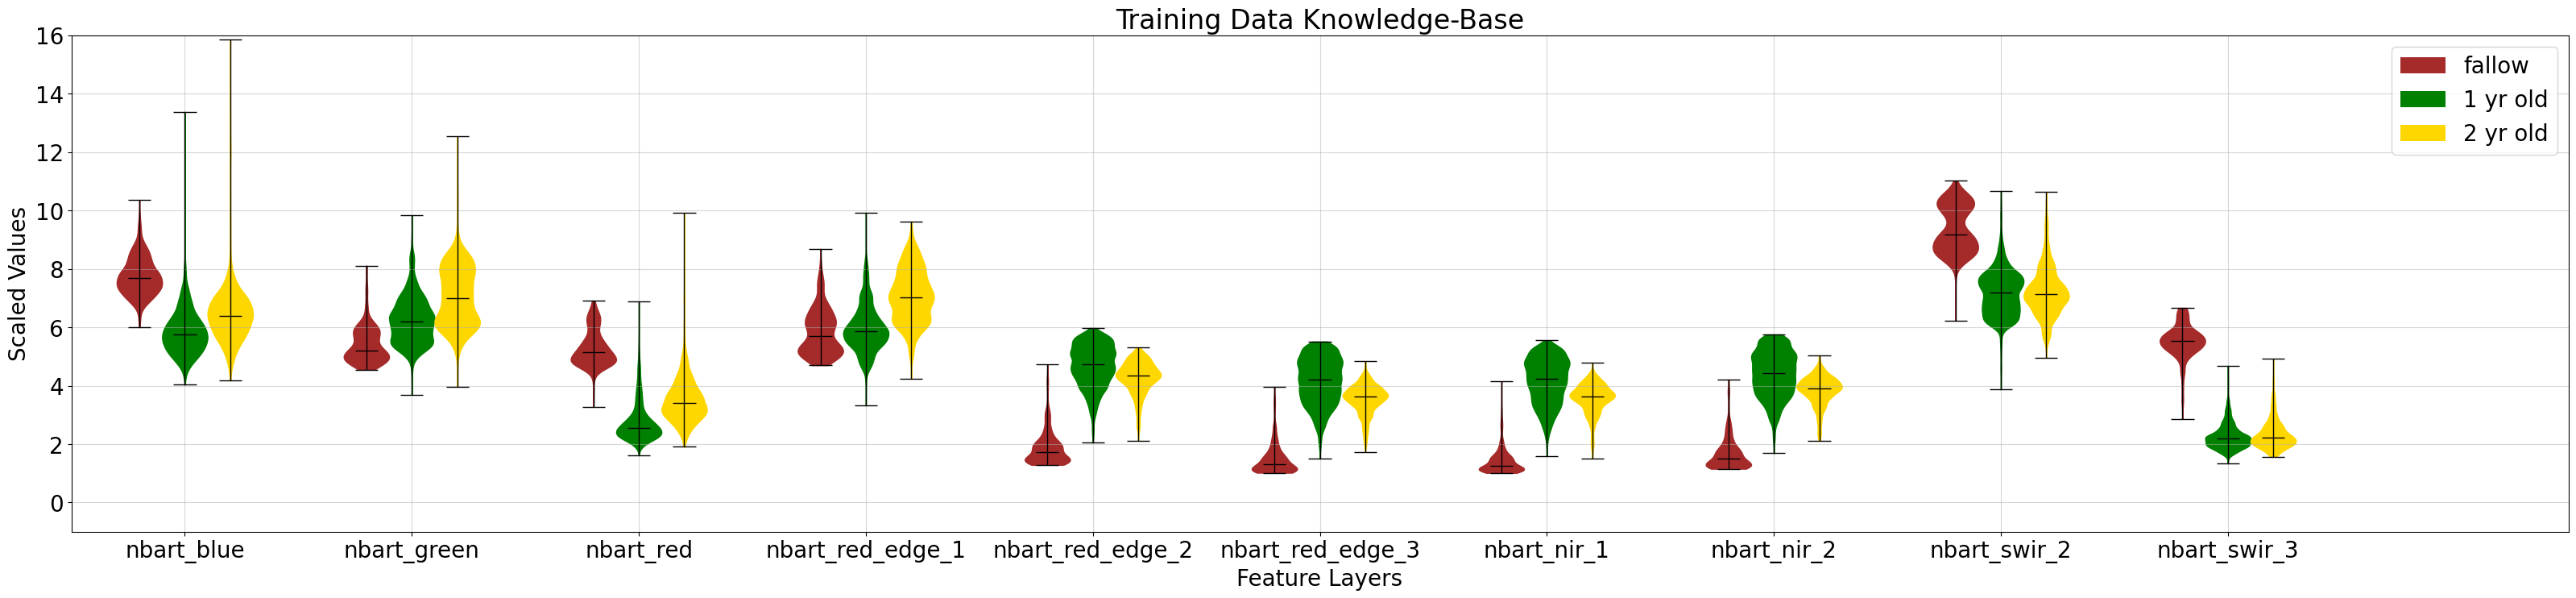

In [17]:
# Generate a random list of colors same length as num of classes
colors = ["brown", "green", "gold"]

# Generate list of offsets & widths for plotting
start = -0.2
end = 0.2
offsets = list(np.linspace(start, end, len(dfs)))
if len(dfs) == 2:
    width = 0.4
else:
    width = np.abs(offsets[0] - offsets[1])

# Create figure and axes
plt.rcParams['font.size'] = 20
fig, ax = plt.subplots(figsize=(40, 8))

for key, color, offset in zip(dfs, colors, offsets):
    # Create violin plots
    pp = ax.violinplot(dfs[key].values,
                       showmedians=True,
                       positions=np.arange(dfs[key].values.shape[1]) + offset,
                       widths=width)
    # Change the colour of the plots
    for pc in pp['bodies']:
        pc.set_facecolor(color)
        pc.set_edgecolor(color)
        pc.set_alpha(1)

    # Change the line style in the plots
    for partname in ('cbars', 'cmins', 'cmaxes', 'cmedians'):
        vp = pp[partname]
        vp.set_edgecolor('black')
        vp.set_linewidth(1)

# Tidy the plot, add a title and legend
ax.set_xticks(np.arange(len(X.columns)))
ax.set_xticklabels(X.columns)
ax.set_xlim(0.5, 11.5)
ax.set_ylim(-1, 16)
ax.set_ylabel("Scaled Values")
ax.set_xlabel("Feature Layers")
ax.tick_params(axis='both', which='major')
ax.set_title("Training Data Knowledge-Base")
ax.grid(alpha=0.5)
ax.legend([Patch(facecolor=c) for c in colors], [key for key in dfs],
          loc='upper right');

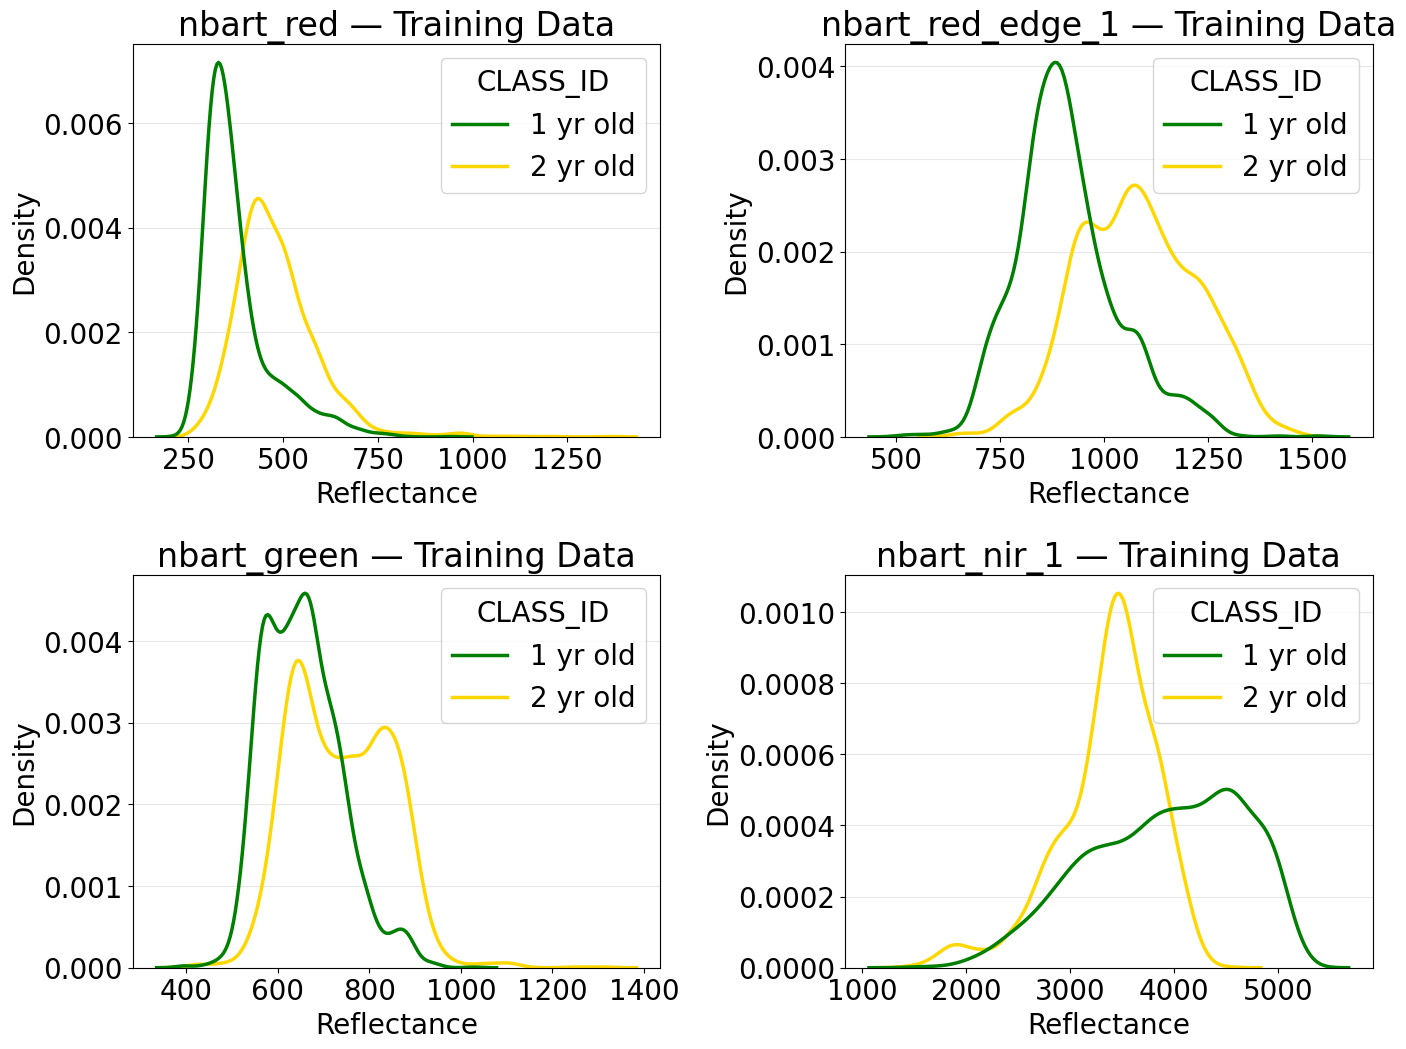

In [26]:


# Bands to compare
bands = [
    'nbart_red',
    'nbart_red_edge_1',
    'nbart_green',
    'nbart_nir_1'
]

# Keep only classes 1 and 2
df_filtered = df[df[field].isin([1, 2])].copy()

# Labels and colours
df_filtered[field] = df_filtered[field].map({
    1: '1 yr old',
    2: '2 yr old'
})

palette = {
    '1 yr old': 'green',
    '2 yr old': 'gold'
}

# Create 2x2 plots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.subplots_adjust(wspace=0.35, hspace=0.35)

axes = axes.flatten()

for ax, band in zip(axes, bands):
    sns.kdeplot(
        data=df_filtered,
        x=band,
        hue=field,
        hue_order=['1 yr old', '2 yr old'],
        palette=palette,
        fill=False,
        linewidth=2.5,
        common_norm=False,
        ax=ax
    )

    ax.set_title(f'{band} — Training Data')
    ax.set_xlabel('Reflectance')
    ax.set_ylabel('Density')
    ax.grid(axis='y', alpha=0.3)

plt.savefig('Results/training-data-overlap.png')
plt.show()